In [11]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd
# 修改为自己的学号
STUDENT_ID = 20244081117
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print (f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print (f"[学号]       {STUDENT_ID}")
print (f"[机器指纹] {MACHINE_FP}")
print (f"[RUN_ID]   {RUN_ID}")

[Conda 环境] py_dateprocessing
[学号]       20244081117
[机器指纹] c8328ad6c13c29ec
[RUN_ID]   20244081117-c8328ad6c13c29ec


实验1：NumPy 数组、娄 数据类型与索引

In [12]:
import numpy as np

print("="*50)
print("1. 创建不同类型数组及属性解释")
print("="*50)

# 分别创建整数、浮点数和布尔值 ndarray
arr_int = np.array([1, 2, 3])
arr_float = np.array([1.0, 2.0, 3.0])
arr_bool = np.array([True, False, True])

# 输出每个数组的 dtype, shape 和 ndim
print(f"整数数组: dtype={arr_int.dtype}, shape={arr_int.shape}, ndim={arr_int.ndim}")
print(f"浮点数组: dtype={arr_float.dtype}, shape={arr_float.shape}, ndim={arr_float.ndim}")
print(f"布尔数组: dtype={arr_bool.dtype}, shape={arr_bool.shape}, ndim={arr_bool.ndim}")

print("\n【解释】：")
print("1. dtype (数据类型): NumPy 数组要求所有元素的数据类型必须一致（同质），这有利于底层 C 语言的高效内存管理。而 Python 列表可以混合存放不同类型（如 [1, 'a', 3.14]）。")
print("2. shape (形状): 表示数组在每一个维度上的大小，如 (3,) 表示一维数组，长度为 3。")
print("3. ndim (维度): 表示数组的轴（维度）的数量，如一维数组 ndim 为 1。")


print("\n" + "="*50)
print("2. 改变数组形状")
print("="*50)

arr = np.arange(12)
print(f"原始一维数组: \n{arr}")

arr_3x4 = arr.reshape(3, 4)
print(f"\n形状为 (3, 4) 的数组: \n{arr_3x4}")

arr_2x3x2 = arr.reshape(2, 3, 2)
print(f"\n形状为 (2, 3, 2) 的数组: \n{arr_2x3x2}")

print("\n【说明】：")
print("改变形状时，元素总数必须保持不变。即：原数组的 size = 新形状各个维度的乘积。例如 12 = 3*4 = 2*3*2。")


print("\n" + "="*50)
print("3. 数组索引与切片")
print("="*50)

# 对形状为 (3, 4) 的数组 arr_3x4 进行操作
print(f"原始 (3, 4) 数组: \n{arr_3x4}")

# 取第 2 行 (索引为 1)
row_2 = arr_3x4[1]
print(f"\n取第 2 行: {row_2}, shape={row_2.shape}")

# 取第 1 至第 3 列 (索引为 0 到 2，切片不含右端，所以是 0:3)
cols_1_to_3 = arr_3x4[:, 0:3]
print(f"\n取第 1 至第 3 列: \n{cols_1_to_3}, \nshape={cols_1_to_3.shape}")

# 取大于 6 的元素 (布尔索引)
greater_than_6 = arr_3x4[arr_3x4 > 6]
print(f"\n取大于 6 的元素: {greater_than_6}, shape={greater_than_6.shape} (一维数组)")


print("\n" + "="*50)
print("4. 逻辑索引")
print("="*50)

arr_10 = np.arange(10)
print(f"原始数组: {arr_10}")

# 使用括号配合 | 和 &
cond1 = (arr_10 < 2) | (arr_10 > 7)
res1 = arr_10[cond1]
print(f"\n【使用 |】选出小于2或大于7的元素: {res1}")

cond2 = (arr_10 > 3) & (arr_10 < 7)
res2 = arr_10[cond2]
print(f"【使用 &】选出大于3且小于7的元素: {res2}")

# 使用 np.logical_or 和 np.logical_and
res3 = arr_10[np.logical_or(arr_10 < 2, arr_10 > 7)]
print(f"\n【使用 np.logical_or】结果: {res3}")

res4 = arr_10[np.logical_and(arr_10 > 3, arr_10 < 7)]
print(f"【使用 np.logical_and】结果: {res4}")


print("\n" + "="*50)
print("5. 乘法对比")
print("="*50)

A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])
print(f"矩阵 A:\n{A}\n矩阵 B:\n{B}")

# * 和 np.multiply() 都是逐元素相乘（Hadamard 积）
print(f"\n【逐元素乘法】A * B: \n{A * B}")
print(f"【逐元素乘法】np.multiply(A, B): \n{np.multiply(A, B)}")

# @ 和 np.matmul() 都是矩阵乘法（线性代数）
print(f"\n【矩阵乘法】A @ B: \n{A @ B}")
print(f"【矩阵乘法】np.matmul(A, B): \n{np.matmul(A, B)}")

print("\n【说明】：")
print("1. 逐元素乘法 (* 或 np.multiply): 两个形状相同的数组，对应位置的元素直接相乘（例如 A[0,0]*B[0,0]）。")
print("2. 矩阵乘法 (@ 或 np.matmul): 遵循线性代数法则，即第 i 行与第 j 列的点积。需满足左矩阵的列数等于右矩阵的行数。")

1. 创建不同类型数组及属性解释
整数数组: dtype=int64, shape=(3,), ndim=1
浮点数组: dtype=float64, shape=(3,), ndim=1
布尔数组: dtype=bool, shape=(3,), ndim=1

【解释】：
1. dtype (数据类型): NumPy 数组要求所有元素的数据类型必须一致（同质），这有利于底层 C 语言的高效内存管理。而 Python 列表可以混合存放不同类型（如 [1, 'a', 3.14]）。
2. shape (形状): 表示数组在每一个维度上的大小，如 (3,) 表示一维数组，长度为 3。
3. ndim (维度): 表示数组的轴（维度）的数量，如一维数组 ndim 为 1。

2. 改变数组形状
原始一维数组: 
[ 0  1  2  3  4  5  6  7  8  9 10 11]

形状为 (3, 4) 的数组: 
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

形状为 (2, 3, 2) 的数组: 
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]

【说明】：
改变形状时，元素总数必须保持不变。即：原数组的 size = 新形状各个维度的乘积。例如 12 = 3*4 = 2*3*2。

3. 数组索引与切片
原始 (3, 4) 数组: 
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

取第 2 行: [4 5 6 7], shape=(4,)

取第 1 至第 3 列: 
[[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]], 
shape=(3, 3)

取大于 6 的元素: [ 7  8  9 10 11], shape=(5,) (一维数组)

4. 逻辑索引
原始数组: [0 1 2 3 4 5 6 7 8 9]

【使用 |】选出小于2或大于7的元素: [0 1 8 9]
【使用 &】选出大于3且小于7的元素: [4 5 6]

【使用 np.logical_or】结果: [0 1 8 9]
【使用 np.logical_and】结果: [4 5 6]

5. 乘

实验2：随机抽样、统计与缺失值

In [13]:
import numpy as np

print("="*50)
print("1. 生成模拟成绩及基本统计")
print("="*50)

np.random.seed(42)

# 生成 1000 个均值为 70、标准差为 10 的正态分布随机数
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.round(scores, 1)

# 使用 np.clip 将数值限制在 0~100 范围内
scores_clipped = np.clip(scores, 0, 100)

# 计算各种统计量
count = len(scores_clipped)
min_val = np.min(scores_clipped)
max_val = np.max(scores_clipped)
mean_val = np.mean(scores_clipped)
std_val = np.std(scores_clipped)
ptp_val = np.ptp(scores_clipped)  # Peak to peak (极差) = max - min

print(f"样本数: {count}")
print(f"最小值: {min_val}")
print(f"最大值: {max_val}")
print(f"均值: {mean_val:.2f}")
print(f"标准差: {std_val:.2f}")
print(f"极差: {ptp_val:.2f}")


print("\n" + "="*50)
print("2. 均匀抽样与加权抽样")
print("="*50)

# 创建 1 到 10 的整数数组
arr = np.arange(1, 11)
print(f"原数组: {arr}")

# 均匀抽样：每个元素被抽中的概率相同 (replace=False 表示不放回)
uniform_sample = np.random.choice(arr, size=5, replace=False)
print(f"均匀抽样结果: {uniform_sample}")

# 加权抽样：假设元素被抽中的概率与其数值大小成正比
# 计算每个元素对应的概率权重
weights = arr / np.sum(arr)
weighted_sample = np.random.choice(arr, size=5, replace=False, p=weights)
print(f"按整数大小成比例加权抽样结果: {weighted_sample}")

print("\n【说明】：")
print("均匀抽样使用默认的 p=None，等概率抽取；加权抽样通过 p 参数传入一个概率数组（总和为1），使得数值大的元素更容易被抽中。")


print("\n" + "="*50)
print("3. 随机排列：保留原数组与原地打乱")
print("="*50)

original_arr = np.array([1, 2, 3, 4, 5])

# 方法一：np.random.permutation 返回打乱后的副本，不改变原数组
permuted_arr = np.random.permutation(original_arr)
print(f"保留原数组 (permutation):")
print(f"  原数组: {original_arr}")
print(f"  打乱后的新数组: {permuted_arr}")

# 重置原数组以便演示第二种方法
original_arr_2 = np.array([1, 2, 3, 4, 5])

# 方法二：np.random.shuffle 原地打乱，直接修改原数组
np.random.shuffle(original_arr_2)
print(f"\n原地打乱 (shuffle):")
print(f"  打印原数组 (已被修改): {original_arr_2}")

print("\n区别：permutation 不改变原数组，返回一个新的打乱后的数组；shuffle 直接在原数组上进行操作，无返回值 (返回 None)。")


print("\n" + "="*50)
print("4. 缺失值 (NaN) 处理")
print("="*50)

# 为了不污染之前的数组，复制一份数据
scores_with_nan = scores_clipped.copy()

# 将第 10、20、30 个值设为 np.nan
scores_with_nan[[9, 19, 29]] = np.nan

# 普通均值（含 nan）
mean_normal = np.mean(scores_with_nan)

# 忽略缺失值后的均值
mean_ignore_nan = np.nanmean(scores_with_nan)

# 统计缺失值个数
nan_count = np.sum(np.isnan(scores_with_nan))

print(f"包含 nan 的普通均值: {mean_normal}")
print(f"忽略 nan 的均值 (nanmean): {mean_ignore_nan:.2f}")
print(f"缺失值 (nan) 个数: {nan_count}")

print("\n说明：")
print("nan (Not a Number) 具有传染性。任何包含 nan 的普通统计函数（如 np.mean, np.sum）计算结果都会变成 nan。因此，处理缺失值时通常需要使用 np.nanmean, np.nansum 等专门忽略 nan 的函数。")


print("\n" + "="*50)
print("5. 整理成内存中的表格变量 (供后续使用)")
print("="*50)

# 创建序号 (1 到 1000)
indices = np.arange(1, len(scores_with_nan) + 1)

# 在内存中整理成结构化数组
table_data = np.column_stack((indices, scores_with_nan))

print(f"整理后的内存表格变量 'table_data' 形状: {table_data.shape}")
print(f"前 5 行数据 (序号, 成绩): \n{table_data[:5]}")


1. 生成模拟成绩及基本统计
样本数: 1000
最小值: 37.6
最大值: 100.0
均值: 70.18
标准差: 9.76
极差: 62.40

2. 均匀抽样与加权抽样
原数组: [ 1  2  3  4  5  6  7  8  9 10]
均匀抽样结果: [ 4  9  2  6 10]
按整数大小成比例加权抽样结果: [10  2  8  9  6]

【说明】：
均匀抽样使用默认的 p=None，等概率抽取；加权抽样通过 p 参数传入一个概率数组（总和为1），使得数值大的元素更容易被抽中。

3. 随机排列：保留原数组与原地打乱
保留原数组 (permutation):
  原数组: [1 2 3 4 5]
  打乱后的新数组: [5 1 3 2 4]

原地打乱 (shuffle):
  打印原数组 (已被修改): [1 5 2 4 3]

区别：permutation 不改变原数组，返回一个新的打乱后的数组；shuffle 直接在原数组上进行操作，无返回值 (返回 None)。

4. 缺失值 (NaN) 处理
包含 nan 的普通均值: nan
忽略 nan 的均值 (nanmean): 70.20
缺失值 (nan) 个数: 3

说明：
nan (Not a Number) 具有传染性。任何包含 nan 的普通统计函数（如 np.mean, np.sum）计算结果都会变成 nan。因此，处理缺失值时通常需要使用 np.nanmean, np.nansum 等专门忽略 nan 的函数。

5. 整理成内存中的表格变量 (供后续使用)
整理后的内存表格变量 'table_data' 形状: (1000, 2)
前 5 行数据 (序号, 成绩): 
[[ 1.  75. ]
 [ 2.  68.6]
 [ 3.  76.5]
 [ 4.  85.2]
 [ 5.  67.7]]


实验3：SciPy数值计算与Matplotlib可视化

1. 线性方程组求解
Scipy 求解结果 (x, y): [2. 3.]
NumPy 验证结果 (x, y): [2. 3.]
验证 A @ x_sol: [9. 8.] (应等于 [9, 8])

2. 方程求根
求正根:
  是否成功: True
  根的值: 1.41421 (即 sqrt(2))
  此时的函数值: -8.88e-16

求负根:
  是否成功: True
  根的值: -1.41421 (即 -sqrt(2))
  此时的函数值: -8.88e-16

3. 函数最小值
优化是否成功: True
极小值点 x: -0.5000
极小值 f(x): 1.7500

【解析结果比较】:
理论极小值点 x: -0.5
理论极小值 f(x): 1.75

4. 独立样本 t 检验
t 统计量: -8.5515
p 值: 3.2930e-15
因为 p 值 (3.2930e-15) < 0.05，拒绝原假设。两组数据存在显著差异。

5. Matplotlib 可视化


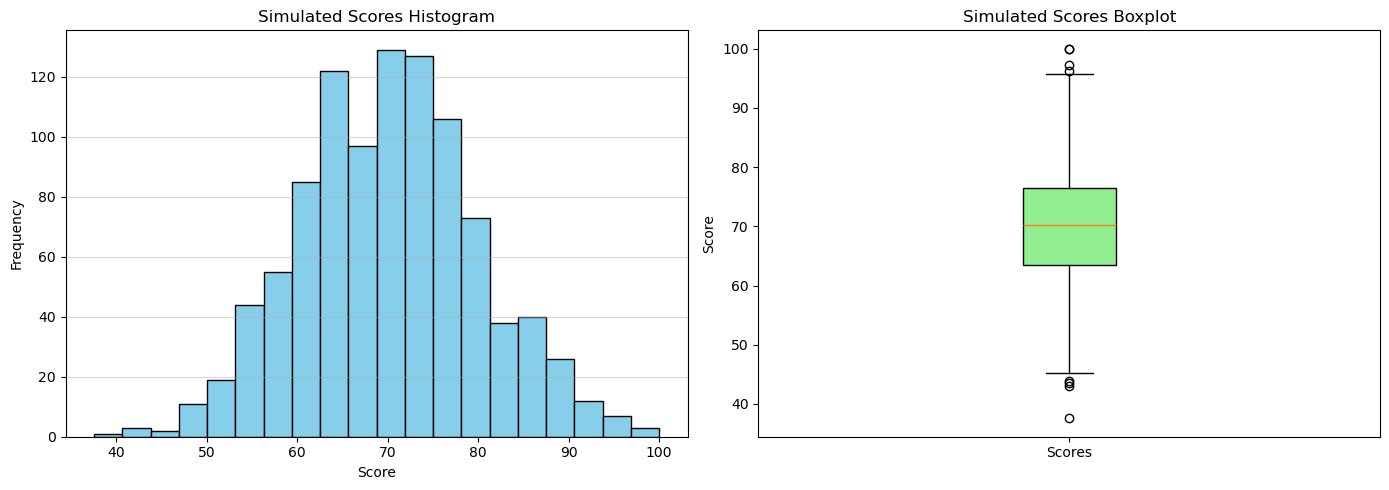

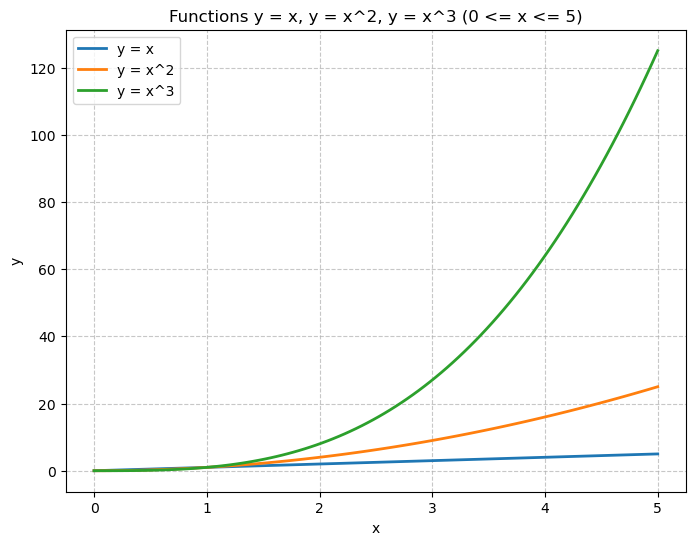

In [14]:
import numpy as np
import scipy.linalg as la
import scipy.optimize as opt
import scipy.stats as stats
import matplotlib.pyplot as plt

print("="*50)
print("1. 线性方程组求解")
print("="*50)

# 方程组: 3x + y = 9, x + 2y = 8
# 转换为矩阵形式 Ax = b
A = np.array([[3, 1], [1, 2]])
b = np.array([9, 8])

x_sol = la.solve(A, b)
print(f"Scipy 求解结果 (x, y): {x_sol}")

x_np = np.linalg.solve(A, b)
print(f"NumPy 验证结果 (x, y): {x_np}")
# 或者通过 A @ x_sol 看是否等于 b
print(f"验证 A @ x_sol: {np.dot(A, x_sol)} (应等于 [9, 8])")


print("\n" + "="*50)
print("2. 方程求根")
print("="*50)

# 目标方程: x^2 - 2 = 0
def func(x):
    return x**2 - 2

# 求正根 (初始猜测值设为 1)
root_pos = opt.root(func, x0=1)
print(f"求正根:")
print(f"  是否成功: {root_pos.success}")
print(f"  根的值: {root_pos.x[0]:.5f} (即 sqrt(2))")
print(f"  此时的函数值: {func(root_pos.x[0]):.2e}")

# 求负根 (初始猜测值设为 -1)
root_neg = opt.root(func, x0=-1)
print(f"\n求负根:")
print(f"  是否成功: {root_neg.success}")
print(f"  根的值: {root_neg.x[0]:.5f} (即 -sqrt(2))")
print(f"  此时的函数值: {func(root_neg.x[0]):.2e}")


print("\n" + "="*50)
print("3. 函数最小值")
print("="*50)

# 目标函数: f(x) = x^2 + x + 2
def f_min(x):
    return x**2 + x + 2

# 使用 minimize 求解 (初始猜测值设为 0)
res = opt.minimize(f_min, x0=0)
print(f"优化是否成功: {res.success}")
print(f"极小值点 x: {res.x[0]:.4f}")
print(f"极小值 f(x): {res.fun:.4f}")

# 解析比较
# 对于 f(x) = ax^2 + bx + c，极值点在 x = -b/(2a)
x_analytical = -1 / (2 * 1)
f_analytical = f_min(x_analytical)
print(f"\n【解析结果比较】:")
print(f"理论极小值点 x: {x_analytical}")
print(f"理论极小值 f(x): {f_analytical}")


print("\n" + "="*50)
print("4. 独立样本 t 检验")
print("="*50)

# 固定随机种子以保证结果可复现
np.random.seed(42)

# 生成两组正态分布模拟样本 (各 100 个)
data1 = np.random.normal(loc=0, scale=1, size=100)
data2 = np.random.normal(loc=1, scale=1, size=100)

# 使用 scipy.stats.ttest_ind 进行独立样本 t 检验
t_stat, p_val = stats.ttest_ind(data1, data2)

print(f"t 统计量: {t_stat:.4f}")
print(f"p 值: {p_val:.4e}")

# 判断
alpha = 0.05
if p_val < alpha:
    print(f"因为 p 值 ({p_val:.4e}) < {alpha}，拒绝原假设。两组数据存在显著差异。")
else:
    print(f"因为 p 值 ({p_val:.4e}) >= {alpha}，无法拒绝原假设。两组数据无显著差异。")


print("\n" + "="*50)
print("5. Matplotlib 可视化")
print("="*50)

# 重新生成实验2的有效成绩数据 
np.random.seed(42)
scores_vis = np.random.normal(loc=70, scale=10, size=1000)
scores_vis = np.clip(scores_vis, 0, 100)

# 创建画布
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (1) 直方图
axes[0].hist(scores_vis, bins=20, color='skyblue', edgecolor='black')
axes[0].set_title('Simulated Scores Histogram')
axes[0].set_xlabel('Score')
axes[0].set_ylabel('Frequency')
axes[0].grid(axis='y', alpha=0.5)

# (2) 箱线图
axes[1].boxplot(scores_vis, vert=True, patch_artist=True, 
                boxprops=dict(facecolor="lightgreen"))
axes[1].set_title('Simulated Scores Boxplot')
axes[1].set_ylabel('Score')
axes[1].set_xticks([1])
axes[1].set_xticklabels(['Scores'])

plt.tight_layout()
plt.show()

# 绘制折线图
x_vals = np.linspace(0, 5, 100)
y1 = x_vals
y2 = x_vals**2
y3 = x_vals**3

plt.figure(figsize=(8, 6))
# 绘制三条线
plt.plot(x_vals, y1, label='y = x', linewidth=2)
plt.plot(x_vals, y2, label='y = x^2', linewidth=2)
plt.plot(x_vals, y3, label='y = x^3', linewidth=2)

# 设置标题、坐标轴标签和图例
plt.title('Functions y = x, y = x^2, y = x^3 (0 <= x <= 5)')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

实验4：pandas Series、DataFrame 与内存中的
CSV 读写

In [15]:
import pandas as pd
import numpy as np

print("="*50)
print("1. 创建 DataFrame 并计算总分与平均分")
print("="*50)

records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82]
}

# 创建 DataFrame，并将 'Name' 列设置为行索引
df = pd.DataFrame(records).set_index('Name')

# 计算总分和平均分
df['Total'] = df[['Math', 'English', 'Python']].sum(axis=1)
df['Average'] = df[['Math', 'English', 'Python']].mean(axis=1)

print(f"行索引 (Index): {df.index.tolist()}")
print(f"列名 (Columns): {df.columns.tolist()}")
print("\n前 3 行数据:")
print(df.head(3))
print("\n基本统计信息:")
print(df.describe())


print("\n" + "="*50)
print("2. 使用 loc 和 iloc 读取与筛选")
print("="*50)

# 读取 Carol 的记录
# loc 使用标签索引 (姓名)
carol_loc = df.loc['Carol']
print(f"使用 loc 读取 Carol 的记录:\n{carol_loc}\n")

# iloc 使用整数位置索引 (Carol 在第 3 行，索引为 2)
carol_iloc = df.iloc[2]
print(f"使用 iloc 读取 Carol 的记录 (第3行):\n{carol_iloc}\n")

# 筛选平均分不低于 80 的学生
high_avg_students = df[df['Average'] >= 80]
print(f"平均分不低于 80 的学生:\n{high_avg_students}")


print("\n" + "="*50)
print("3. 计算列均值和行均值")
print("--"*25)

# 计算三科成绩的列均值 (axis=0 沿着行方向计算，即每列的平均值)
col_means = df[['Math', 'English', 'Python']].mean(axis=0)
print(f"三科成绩的列均值 (每科平均分):\n{col_means}\n")

# 计算每名学生的行均值 (axis=1 沿着列方向计算，即每行的平均值)
row_means = df[['Math', 'English', 'Python']].mean(axis=1)
print(f"每名学生的行均值:\n{row_means}")


print("\n" + "="*50)
print("4. 使用 apply 和 agg 计算")
print("="*50)

# 使用 apply() 计算每名学生的三科最高分
df['Max_Score'] = df[['Math', 'English', 'Python']].apply(max, axis=1)
print(f"每名学生的三科最高分:\n{df['Max_Score']}\n")

# 使用 agg() 一次性得到每科的最小值、均值和最大值
agg_results = df[['Math', 'English', 'Python']].agg(['min', 'mean', 'max'])
print(f"每科的最小值、均值和最大值:\n{agg_results}\n")

# 任选一列使用 rank() 给学生排名（例如对 Math 进行降序排名）
df['Math_Rank'] = df['Math'].rank(ascending=False)
print(f"按 Math 成绩降序排名的结果:\n{df[['Math', 'Math_Rank']]}")


print("\n" + "="*50)
print("5. 按 Group 分组统计与 transform")
print("="*50)

# 按 Group 分组，统计每组人数和三科平均分
group_stats = df.groupby('Group').agg(
    Count=('Math', 'count'), # 统计人数
    Math_Mean=('Math', 'mean'),
    English_Mean=('English', 'mean'),
    Python_Mean=('Python', 'mean')
)
print(f"按 Group 分组的统计信息:\n{group_stats}\n")

# 使用 transform('mean') 为每行增加其所在组的 Python 平均分
df['Group_Python_Mean'] = df.groupby('Group')['Python'].transform('mean')
print(f"增加所在组 Python 平均分后的数据:\n{df[['Group', 'Python', 'Group_Python_Mean']]}")


print("\n" + "="*50)
print("6. 使用 filter 保留特定组")
print("="*50)

# filter 接收一个函数，该函数作用于组名 (Group)，返回布尔值
filtered_groups = df.groupby('Group').filter(lambda g: g['Python'].mean() >= 80)

print("保留的组和学生 (即 Python 平均分 >= 80 的所有学生):")
print(filtered_groups[['Group', 'Python']])


print("\n" + "="*50)
print("7. 协方差矩阵与皮尔逊相关系数矩阵")
print("="*50)

# 选择三科成绩
subjects = df[['Math', 'English', 'Python']]

# 计算协方差矩阵
cov_matrix = subjects.cov()
print(f"协方差矩阵:\n{cov_matrix}\n")

# 计算皮尔逊相关系数矩阵
corr_matrix = subjects.corr(method='pearson')
print(f"皮尔逊相关系数矩阵:\n{corr_matrix}\n")

print("解释说明：")
print("我们选择 'Math' 和 'English' 这一对科目来解释：")
print(f"1. 协方差为 {cov_matrix.loc['Math', 'English']:.2f}，符号为正。这意味着这两门成绩呈正相关趋势，即数学成绩较高的学生，英语成绩也倾向于较高。")
print(f"2. 相关系数为 {corr_matrix.loc['Math', 'English']:.2f}。相关系数的绝对值在 [-1, 1] 之间，它消除了量纲的影响，衡量的是线性相关性的强弱。该值大于 0 说明正相关，距离 1 越近说明线性关系越强。")

1. 创建 DataFrame 并计算总分与平均分
行索引 (Index): ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名 (Columns): ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前 3 行数据:
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息:
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.00